# DS-A3 | Regression Baseline and Diagnostics

**Data.** Table S1 (bulk rock) from the published supplementary workbook of Ali et al., *Journal of Asian Earth Sciences*, DOI 10.1016/j.jseaes.2025.106927. The workbook is not redistributed in this repository (see README).

## 1. Question and scope

**Question.** Can bulk ∑REY (ppm) in the 29 samples of the Early Cambrian Kakul Garlaniyan phosphorite layers be predicted from non-REY trace and minor elements, and where does that prediction stop being reliable?

**What this notebook is.** A small, interpretable baseline study on published data: a naive baseline, a leakage-free frozen split, linear / ridge / lasso candidates tuned without the test set, diagnostics, and an explicit claim boundary. It is retrospective and exploratory, not preregistered.

**What it is not.** It is not a causal analysis, not a validated prediction tool, and says nothing about phosphorites outside this section. With 29 samples, every estimate here is uncertain.

**Decisions made before any model was fitted** (the exploratory look at all 29 samples that informed two of them is disclosed in Section 3):

| Item | Decision |
|---|---|
| Target | ∑REY in ppm, raw scale |
| Predictors | 35 non-REY trace/minor elements; log10, then standardised inside each CV fold |
| Excluded | REY elements and ratios (leakage); major oxides and LOI (only 14 of 29 samples); Ag, Tl, Hf (below-detection entries) |
| Split | Stratified by layer; 2 test samples per layer; seed 42; frozen in `data/splits/split.csv` |
| Naive baselines | Training mean; training mean per layer |
| Candidates | OLS on all 35 predictors (expected to overfit), OLS on the k best predictors, ridge, lasso |
| Tuning | 5-fold x 10-repeat cross-validation on the training samples only; metric RMSE (ppm) |
| Selection rule | Lowest mean CV RMSE among the tuned candidates. The test set is never used to choose a model. |
| Boundary check | Leave-one-layer-out on the training samples (reported, not used for selection) |


In [1]:
import json, hashlib, platform, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy, sklearn, statsmodels
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import GridSearchCV, RepeatedKFold, KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

SEED = 42
ROOT = Path.cwd()                     # the notebook must run with the project folder as working directory
RES, FIG, SPL = ROOT / "results", ROOT / "figures", ROOT / "data" / "splits"
for d in (RES, FIG, SPL):
    d.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("Working directory:", ROOT)

Working directory: e:\Asssessment Team\PhD\Data Science\DS-A3


## 2. Load and validate

In [2]:
TARGET = "∑REY"      # copy this symbol from the sheet header if you ever retype it
REY = ["La", "Ce", "Pr", "Nd", "Sm", "Eu", "Gd", "Tb", "Dy", "Y", "Ho", "Er", "Tm", "Yb", "Lu"]
# Ratio columns computed from the REY (REE ratios and anomalies, most PAAS-normalised) or from predictors (Sr/Ca, Rb/Sr): excluded as predictors
DERIVED = ["Ce/Ce*", "Pr/Pr*", "Y/Y*", "Eu/Eu*", "Y/Ho", "La/Yb", "La/Sm", "Sr/Ca", "Rb/Sr"]
MAJOR = ["Al2O3", "BaO", "CaO", "F", "TFe2O3", "K2O", "MgO", "MnO", "Na2O", "NiO", "P2O5",
         "SiO2", "SnO2", "SO3", "SrO", "TiO2", "LOI 1000"]
CENSORED = ["Ag", "Tl", "Hf"]
PREDICTORS = ["Al %", "As", "Be", "Bi", "Ca %", "Cd", "Co", "Cr", "Cs", "Cu", "Fe %", "Ga", "Ge",
              "K %", "Li", "Mg %", "Mn", "Mo", "Na %", "Ni", "Pb", "Rb", "S %", "Sb", "Sc", "Sr",
              "Th", "Ti %", "W", "Zn", "Ba", "U", "V", "Zr", "Nb"]
FORBIDDEN = set(REY + DERIVED + MAJOR + CENSORED + [TARGET])

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

names = ["Supplementary file.xlsx", "Supplementary_file.xlsx"]
paths = [ROOT / "data" / "raw" / n for n in names] + [ROOT / n for n in names]
DATA = next((p for p in paths if p.exists()), None)
assert DATA is not None, "Original supplementary workbook not found. Put it in data/raw/ (see README)."
DATA_SHA256 = sha256(DATA)
print("Workbook:", DATA.relative_to(ROOT))
print("SHA-256 :", DATA_SHA256)

Workbook: data\raw\Supplementary file.xlsx
SHA-256 : 17343594cd7317c950a5ab7fd713c0928859a0a333ac20798d9da6ce645dd18b


In [3]:
raw = pd.read_excel(DATA, sheet_name=0, header=1)            # row 2 of the sheet holds the column names
raw.columns = [str(c).strip() for c in raw.columns]
df = raw.rename(columns={raw.columns[0]: "layer", "S#No": "sample", "Lithology": "lithology"})
df["layer"] = df["layer"].ffill().astype(str).str.strip()    # layer is written only on the first row of each block
df["sample"] = df["sample"].astype(str).str.strip()
df["lithology"] = df["lithology"].astype(str).str.strip()
assert df["sample"].is_unique and len(df) == 29
target = pd.to_numeric(df[TARGET], errors="raise")

print("Samples per layer:", df.groupby("layer").size().to_dict())
print("Lithology counts :", df["lithology"].value_counts().to_dict())
print("Samples with major oxides recorded:", int(df[MAJOR].notna().all(axis=1).sum()), "of", len(df))
df[["sample", "layer", "lithology"]].head()

Samples per layer: {'LPL': 10, 'MPL': 11, 'UPL': 8}
Lithology counts : {'Phosphorite': 20, 'Dolomatic Phosphorite': 6, 'Chert': 2, 'Cherty Phosphorite': 1}
Samples with major oxides recorded: 14 of 29


,sample,layer,lithology
0,KG-1,LPL,Phosphorite
1,KG-2,LPL,Cherty Phosphorite
2,KG-3,LPL,Dolomatic Phosphorite
3,KG-4,LPL,Chert
4,KG-5,LPL,Chert


## 3. Leakage audit

The target is ∑REY, and the workbook also contains the individual REY concentrations and ratios computed from them. If any of those were used as predictors, the "model" would just re-add its own answer. The checks below are run in code, not assumed.

In [4]:
rey_num = df[REY].apply(pd.to_numeric, errors="raise")
max_err = float((rey_num.sum(axis=1) - target).abs().max())
yho_err = float((rey_num["Y"] / rey_num["Ho"] - pd.to_numeric(df["Y/Ho"], errors="raise")).abs().max())
X_all = df[PREDICTORS].apply(pd.to_numeric, errors="raise")   # raises if a '<' entry slips in

audit = pd.DataFrame([
    ("∑REY equals the sum of La..Lu + Y in the file", max_err < 1e-6, f"max abs difference {max_err:.1e} ppm"),
    ("Y/Ho equals Y divided by Ho", yho_err < 1e-6, f"max abs difference {yho_err:.1e}"),
    ("No predictor is a REY, derived ratio, major oxide, censored column or the target", FORBIDDEN.isdisjoint(PREDICTORS), f"{len(PREDICTORS)} predictors"),
    ("Predictors have no missing values", int(X_all.isna().sum().sum()) == 0, ""),
    ("Predictors are strictly positive, so log10 is safe", bool((X_all > 0).all().all()), f"minimum value {float(X_all.min().min())}"),
], columns=["check", "passed", "detail"])
audit.to_csv(RES / "leakage_audit.csv", index=False)

excluded = pd.DataFrame([
    ("Target", TARGET, "the quantity being predicted"),
    ("REY elements", ", ".join(REY), "the target is exactly their sum: direct leakage"),
    ("Derived ratios", ", ".join(DERIVED), "computed from REY (leakage) or from other predictors (redundant)"),
    ("Major oxides and LOI", f"{len(MAJOR)} columns", "recorded for only 14 of 29 samples; using them would halve the data"),
    ("Below-detection columns", ", ".join(CENSORED), "contain '<' entries, which are not numbers"),
], columns=["group", "columns", "reason"])
excluded.to_csv(RES / "excluded_columns.csv", index=False)
assert audit["passed"].all(), "A leakage check failed"
display(audit); display(excluded)

,check,passed,detail
0,∑REY equals the sum of La..Lu + Y in the file,True,max abs difference 5.7e-14 ppm
1,Y/Ho equals Y divided by Ho,True,max abs difference 0.0e+00
2,"No predictor is a REY, derived ratio, major ox...",True,35 predictors
3,Predictors have no missing values,True,
4,"Predictors are strictly positive, so log10 is ...",True,minimum value 0.005


,group,columns,reason
0,Target,∑REY,the quantity being predicted
1,REY elements,"La, Ce, Pr, Nd, Sm, Eu, Gd, Tb, Dy, Y, Ho, Er,...",the target is exactly their sum: direct leakage
2,Derived ratios,"Ce/Ce*, Pr/Pr*, Y/Y*, Eu/Eu*, Y/Ho, La/Yb, La/...",computed from REY (leakage) or from other pred...
3,Major oxides and LOI,17 columns,recorded for only 14 of 29 samples; using them...
4,Below-detection columns,"Ag, Tl, Hf","contain '<' entries, which are not numbers"


## 4. Frozen split

In [5]:
rng = np.random.default_rng(SEED)
test_ids = []
for layer, g in df.groupby("layer", sort=True):
    test_ids += [str(s) for s in rng.choice(sorted(g["sample"]), size=2, replace=False)]

data = pd.concat([df[["sample", "layer", "lithology"]], target.rename(TARGET), X_all], axis=1)
data["subset"] = np.where(data["sample"].isin(test_ids), "test", "train")
data[["sample", "layer", "lithology", "subset"]].to_csv(SPL / "split.csv", index=False)

train = data[data.subset == "train"].reset_index(drop=True)
test = data[data.subset == "test"].reset_index(drop=True)
assert set(train["sample"]).isdisjoint(test["sample"]) and len(train) == 23 and len(test) == 6
Xtr, ytr, Xte, yte = train[PREDICTORS], train[TARGET].values, test[PREDICTORS], test[TARGET].values

print("Test samples:", sorted(test_ids))
display(pd.crosstab(data["layer"], data["subset"]))
display(pd.crosstab(data["lithology"], data["subset"]))
N_TEST_CHERT = int(test["lithology"].str.contains("Chert").sum())
print("Chert-bearing samples in the test set:", N_TEST_CHERT, "| in the training set:", int(train["lithology"].str.contains("Chert").sum()))

Test samples: ['KG-1', 'KG-15', 'KG-21', 'KG-22', 'KG-27', 'KG-7']


subset,test,train
layer,,
LPL,2,8
MPL,2,9
UPL,2,6


subset,test,train
lithology,,
Chert,0,2
Cherty Phosphorite,0,1
Dolomatic Phosphorite,1,5
Phosphorite,5,15


Chert-bearing samples in the test set: 0 | in the training set: 3


The split is stratified by layer but not by lithology. All three chert-bearing samples fall in the training set, so **the test set cannot show how the models behave on cherts**. This is a property of the split, which was frozen before any model was scored and is not re-drawn to fix it. Chert behaviour is examined through cross-validation residuals and the leave-one-layer-out check instead.

## 5. Baselines and candidate models (tuned on the training set only)

All scaling, transformation, feature selection and tuning happen inside cross-validation folds on the 23 training samples. The target is standardised inside the model so that one penalty grid works for ridge and lasso; predictions are returned in ppm.

**A tuning decision to disclose.** The grid for k (OLS on the k best predictors) was first limited to k <= 8. A trial run, made with AI help before this notebook was finalised, showed the best k at that edge, so the grid was widened to k <= 22. The reason was a training-CV result, but the same trial run also displayed test-set scores, so the decision was not made blind to them. The cell below checks every grid for edge optima automatically.

In [6]:
CV = RepeatedKFold(n_splits=5, n_repeats=10, random_state=SEED)        # tuning folds, training samples only
INNER_CV = RepeatedKFold(n_splits=5, n_repeats=3, random_state=SEED)   # smaller, for leave-one-layer-out

def rmse(y, p):
    return float(np.sqrt(mean_squared_error(y, p)))

def pipe(model, k_select=False):
    steps = [("log", FunctionTransformer(np.log10, feature_names_out="one-to-one")), ("scale", StandardScaler())]
    if k_select:
        steps.append(("select", SelectKBest(f_regression, k=2)))
    steps.append(("model", model))
    return TransformedTargetRegressor(regressor=Pipeline(steps), transformer=StandardScaler())

CANDIDATES = {
    "ols_all":   (pipe(LinearRegression()), None, "OLS, all 35 predictors (23 samples: under-determined)"),
    "ols_kbest": (pipe(LinearRegression(), k_select=True), {"regressor__select__k": [1, 2, 3, 4, 5, 8, 12, 16, 22]}, "OLS on the k best predictors"),
    "ridge":     (pipe(Ridge()), {"regressor__model__alpha": np.logspace(-2, 3, 40)}, "Ridge, all 35 predictors"),
    "lasso":     (pipe(Lasso(max_iter=50000)), {"regressor__model__alpha": np.logspace(-3, 0, 40)}, "Lasso, all 35 predictors"),
}

def layer_mean(tr_df, te_df):
    m = tr_df.groupby("layer")[TARGET].mean()
    return te_df["layer"].map(m).values

print("CV folds per tuning run:", CV.get_n_splits(Xtr))
for name, (_, grid, desc) in CANDIDATES.items():
    print(f"{name:10s} {desc}")

CV folds per tuning run: 50
ols_all    OLS, all 35 predictors (23 samples: under-determined)
ols_kbest  OLS on the k best predictors
ridge      Ridge, all 35 predictors
lasso      Lasso, all 35 predictors


In [7]:
fitted, cv_stats, tuning_rows = {}, {}, []
with warnings.catch_warnings(record=True) as tuning_warnings:
    warnings.simplefilter("always")
    for name, (est, grid, _) in CANDIDATES.items():
        if grid:
            gs = GridSearchCV(est, grid, cv=CV, scoring="neg_root_mean_squared_error", refit=True, n_jobs=1).fit(Xtr, ytr)
            r = pd.DataFrame(gs.cv_results_); r.insert(0, "model", name); tuning_rows.append(r)
            i = gs.best_index_
            cv_stats[name] = (float(-gs.cv_results_["mean_test_score"][i]), float(gs.cv_results_["std_test_score"][i]), gs.best_params_)
            fitted[name] = gs.best_estimator_
        else:
            s = -cross_val_score(est, Xtr, ytr, cv=CV, scoring="neg_root_mean_squared_error")
            cv_stats[name] = (float(s.mean()), float(s.std()), {})
            fitted[name] = clone(est).fit(Xtr, ytr)
    s = -cross_val_score(DummyRegressor(strategy="mean"), Xtr, ytr, cv=CV, scoring="neg_root_mean_squared_error")
    cv_stats["naive_mean"] = (float(s.mean()), float(s.std()), {})
    fitted["naive_mean"] = DummyRegressor(strategy="mean").fit(Xtr, ytr)
    fold_rmse = [rmse(train.loc[b, TARGET], layer_mean(train.iloc[a], train.iloc[b])) for a, b in CV.split(train)]
    cv_stats["layer_mean"] = (float(np.mean(fold_rmse)), float(np.std(fold_rmse)), {})

tuning = pd.concat(tuning_rows)
tuning.to_csv(RES / "tuning_runs.csv", index=False)       # every tuning run is kept

# did any best value land on the edge of its grid?  (train-CV information only)
edge_msgs = []
for name, (est, grid, _) in CANDIDATES.items():
    if grid:
        (pname, values), = grid.items()
        best = cv_stats[name][2][pname]
        if best == list(values)[0] or best == list(values)[-1]:
            edge_msgs.append(f"{name}: best value {best} is at the edge of its grid")
print("Grid-edge check:", edge_msgs or "all tuned values are strictly inside their grids")
Z = StandardScaler().fit_transform(np.log10(Xtr))
sv = np.linalg.svd(Z, compute_uv=False)
TRAIN_RANK = int((sv > sv[0] * 1e-10).sum())
print(f"Training design matrix: {len(Xtr)} samples, {len(PREDICTORS)} predictors, rank {TRAIN_RANK} (max {len(Xtr) - 1})")
print("Warnings during tuning:", len(tuning_warnings))
pd.DataFrame({m: {"cv_rmse_mean": v[0], "cv_rmse_sd": v[1], "best_params": {k: float(x) for k, x in v[2].items()}} for m, v in cv_stats.items()}).T

Grid-edge check: all tuned values are strictly inside their grids
Training design matrix: 23 samples, 35 predictors, rank 22 (max 22)
Warnings during tuning: 0


,cv_rmse_mean,cv_rmse_sd,best_params
ols_all,80.361775,30.698029,{}
ols_kbest,55.544463,19.198589,{'regressor__select__k': 8.0}
ridge,61.623535,15.367037,{'regressor__model__alpha': 11.937766417144358}
lasso,51.898273,17.124505,{'regressor__model__alpha': 0.05878016072274915}
naive_mean,181.347111,46.712044,{}
layer_mean,182.86587,47.247354,{}


### Selection rule and the single scoring of the test set

In [8]:
TUNED = ["ols_all", "ols_kbest", "ridge", "lasso"]
SELECTED = min(TUNED, key=lambda m: cv_stats[m][0])       # rule fixed in Section 1: lowest mean CV RMSE
print("Model selected by the pre-declared rule (lowest CV RMSE):", SELECTED)

preds = {n: m.predict(Xte) for n, m in fitted.items()}      # the test set is scored here, once, after selection
preds["layer_mean"] = layer_mean(train, test)
rng_boot = np.random.default_rng(SEED)

def boot_ci(y, p, n=2000):
    idx = rng_boot.integers(0, len(y), size=(n, len(y)))
    r = [rmse(y[i], p[i]) for i in idx]
    return float(np.percentile(r, 2.5)), float(np.percentile(r, 97.5))

def n_features(name, m):
    if name in ("naive_mean", "layer_mean"):
        return 0
    steps = m.regressor_.named_steps
    if name == "lasso":
        return int((steps["model"].coef_ != 0).sum())
    if name == "ols_kbest":
        return int(steps["select"].get_support().sum())
    return len(PREDICTORS)

rows = []
for name in ["naive_mean", "layer_mean", "ols_all", "ols_kbest", "ridge", "lasso"]:
    p = preds[name]
    lo, hi = boot_ci(yte, p)
    tr_pred = layer_mean(train, train) if name == "layer_mean" else fitted[name].predict(Xtr)
    rows.append({"model": name, "n_features_used": n_features(name, fitted.get(name)),
                 "best_params": json.dumps({k: float(v) for k, v in cv_stats[name][2].items()}),
                 "cv_rmse_mean": cv_stats[name][0], "cv_rmse_sd": cv_stats[name][1], "train_rmse": rmse(ytr, tr_pred),
                 "test_rmse": rmse(yte, p), "test_rmse_ci95_lo": lo, "test_rmse_ci95_hi": hi,
                 "test_mae": float(mean_absolute_error(yte, p)), "test_r2": float(r2_score(yte, p))})
comp = pd.DataFrame(rows)
naive_cv = comp.loc[comp.model == "naive_mean", "cv_rmse_mean"].iloc[0]
naive_test = comp.loc[comp.model == "naive_mean", "test_rmse"].iloc[0]
comp["cv_gain_vs_naive_pct"] = 100 * (1 - comp["cv_rmse_mean"] / naive_cv)
comp["test_gain_vs_naive_pct"] = 100 * (1 - comp["test_rmse"] / naive_test)
comp["selected_by_cv_rule"] = comp["model"] == SELECTED

pd.DataFrame({"sample": test["sample"], "layer": test["layer"], "lithology": test["lithology"], "y_true": yte,
              **{f"pred_{n}": p for n, p in preds.items()}}).to_csv(RES / "test_predictions.csv", index=False)
comp.round(2)

Model selected by the pre-declared rule (lowest CV RMSE): lasso


,model,n_features_used,best_params,cv_rmse_mean,cv_rmse_sd,train_rmse,test_rmse,test_rmse_ci95_lo,test_rmse_ci95_hi,test_mae,test_r2,cv_gain_vs_naive_pct,test_gain_vs_naive_pct,selected_by_cv_rule
0,naive_mean,0,{},181.35,46.71,182.22,169.37,115.73,211.05,148.51,-0.07,0.00,0.00,False
1,layer_mean,0,{},182.87,47.25,164.55,142.60,86.43,182.56,122.98,0.24,-0.84,15.80,False
2,ols_all,35,{},80.36,30.70,0.00,101.40,29.79,167.51,68.48,0.62,55.69,40.13,False
3,ols_kbest,8,"{""regressor__select__k"": 8.0}",55.54,19.20,34.25,86.61,32.59,136.95,64.08,0.72,69.37,48.86,False
4,ridge,35,"{""regressor__model__alpha"": 11.937766417144358}",61.62,15.37,37.49,42.83,19.30,62.05,35.22,0.93,66.02,74.71,False
5,lasso,8,"{""regressor__model__alpha"": 0.05878016072274915}",51.90,17.12,38.52,82.06,32.05,118.00,63.61,0.75,71.38,51.55,True


### Leave-one-layer-out boundary check (training samples only)

Train on two layers, predict the third. This is a harsher test than the random within-layer split, because neighbouring samples in a section are chemically similar. Alpha and k are re-tuned inside each fold with a smaller inner CV. It is reported, not used for selection.

In [9]:
lolo = {}
with warnings.catch_warnings(record=True) as lolo_warnings:
    warnings.simplefilter("always")
    for L_out in sorted(train["layer"].unique()):
        a, b = train[train.layer != L_out], train[train.layer == L_out]
        res = {"naive_mean": rmse(b[TARGET], np.full(len(b), a[TARGET].mean())), "layer_mean": np.nan}
        for name, (est, grid, _) in CANDIDATES.items():
            m = GridSearchCV(est, grid, cv=INNER_CV, scoring="neg_root_mean_squared_error", n_jobs=1).fit(a[PREDICTORS], a[TARGET]) if grid else clone(est).fit(a[PREDICTORS], a[TARGET])
            res[name] = rmse(b[TARGET], m.predict(b[PREDICTORS]))
        lolo[L_out] = res
lolo_df = pd.DataFrame(lolo)
lolo_df.to_csv(RES / "leave_one_layer_out_rmse.csv")
for L_out in lolo_df.columns:
    comp[f"lolo_rmse_{L_out}"] = comp["model"].map(lolo_df[L_out])
comp.to_csv(RES / "model_comparison.csv", index=False)
print("Warnings during leave-one-layer-out:", len(lolo_warnings))
display(lolo_df.round(1))
display(train.groupby("layer").agg(n=("sample", "size"), n_chert_bearing=("lithology", lambda s: int(s.str.contains("Chert").sum())), mean_REY=(TARGET, "mean")).round(1))

Warnings during leave-one-layer-out: 0


,LPL,MPL,UPL
naive_mean,241.4,150.5,200.1
layer_mean,NaN,NaN,NaN
ols_all,128.3,103.4,78.2
ols_kbest,96.8,92.9,93.1
ridge,58.4,70.1,85.9
lasso,102.4,49.0,76.0


,n,n_chert_bearing,mean_REY
layer,,,
LPL,8,3,276.3
MPL,9,0,355.7
UPL,6,0,478.9


## 6. Diagnostics of the selected model

Residuals are **out-of-fold**: each training sample is predicted by models that did not see it, averaged over the 10 CV repeats. The tuned hyper-parameters were chosen on the same data, so these residuals are slightly optimistic. Test-set residuals are shown separately.

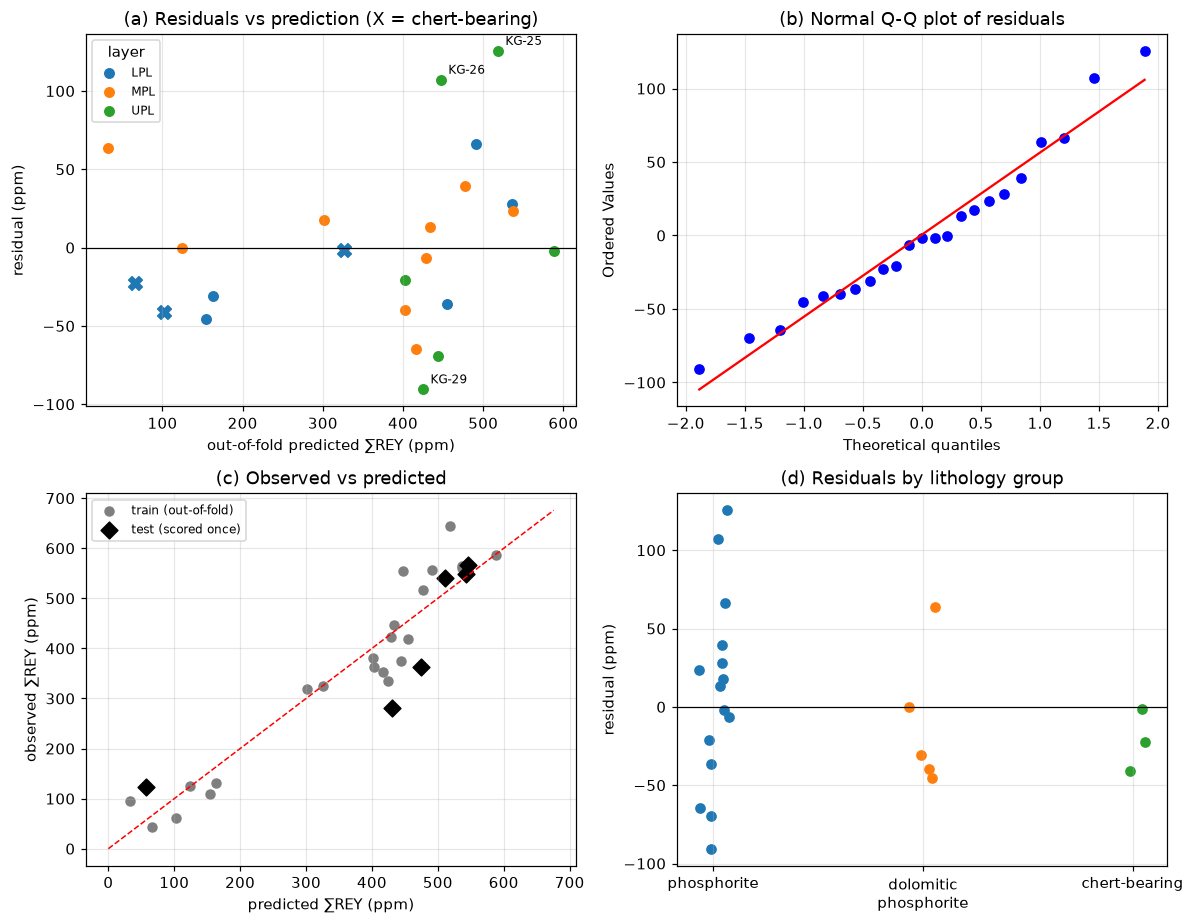

Shapiro-Wilk on residuals: W = 0.964, p = 0.545 (n = 23; low power)


In [10]:
def oof_predictions(est, X, y, cv):
    s, c = np.zeros(len(y)), np.zeros(len(y))
    for tr_i, te_i in cv.split(X):
        m = clone(est).fit(X.iloc[tr_i], y[tr_i])
        s[te_i] += m.predict(X.iloc[te_i]); c[te_i] += 1
    return s / c

best_unfitted = clone(fitted[SELECTED])
oof = oof_predictions(best_unfitted, Xtr, ytr, CV)
resid = ytr - oof
test_pred = fitted[SELECTED].predict(Xte)
test_resid = yte - test_pred
oof_df = train[["sample", "layer", "lithology"]].assign(y=ytr, oof=oof, resid=resid)
chert = oof_df["lithology"].str.contains("Chert").values
LAYER_COL = {"LPL": "tab:blue", "MPL": "tab:orange", "UPL": "tab:green"}

fig, ax = plt.subplots(2, 2, figsize=(11, 8.5))
a = ax[0, 0]
for L, c in LAYER_COL.items():
    m = (oof_df.layer == L).values
    a.scatter(oof[m & ~chert], resid[m & ~chert], c=c, s=38, label=L)
    a.scatter(oof[m & chert], resid[m & chert], c=c, s=80, marker="X")
for i in np.argsort(-np.abs(resid))[:3]:
    a.annotate(oof_df["sample"][i], (oof[i], resid[i]), textcoords="offset points", xytext=(5, 4), fontsize=8)
a.axhline(0, c="k", lw=0.8); a.set_xlabel("out-of-fold predicted ∑REY (ppm)"); a.set_ylabel("residual (ppm)")
a.set_title("(a) Residuals vs prediction (X = chert-bearing)"); a.legend(title="layer", fontsize=8)
stats.probplot(resid, dist="norm", plot=ax[0, 1]); ax[0, 1].set_title("(b) Normal Q-Q plot of residuals")
b = ax[1, 0]
b.scatter(oof, ytr, c="tab:gray", s=34, label="train (out-of-fold)")
b.scatter(test_pred, yte, c="k", s=60, marker="D", label="test (scored once)")
lim = [0, max(ytr.max(), yte.max()) * 1.05]
b.plot(lim, lim, "r--", lw=1); b.set_xlabel("predicted ∑REY (ppm)"); b.set_ylabel("observed ∑REY (ppm)")
b.set_title("(c) Observed vs predicted"); b.legend(fontsize=8)
d = ax[1, 1]
grp = np.where(oof_df.lithology.str.contains("Chert"), "chert-bearing", np.where(oof_df.lithology.str.contains("Dolo"), "dolomitic phosphorite", "phosphorite"))
oof_df["lith_group"] = grp
for k, g in enumerate(["phosphorite", "dolomitic phosphorite", "chert-bearing"]):
    vals = oof_df.loc[oof_df.lith_group == g, "resid"].values
    d.scatter(np.full(len(vals), k) + np.random.default_rng(SEED).uniform(-0.08, 0.08, len(vals)), vals, s=36)
d.axhline(0, c="k", lw=0.8); d.set_xticks([0, 1, 2]); d.set_xticklabels(["phosphorite", "dolomitic\nphosphorite", "chert-bearing"])
d.set_ylabel("residual (ppm)"); d.set_title("(d) Residuals by lithology group")
plt.tight_layout(); plt.savefig(FIG / "diagnostics_residuals.png", bbox_inches="tight", dpi=150); plt.show()
sw = stats.shapiro(resid)
print(f"Shapiro-Wilk on residuals: W = {sw.statistic:.3f}, p = {sw.pvalue:.3f} (n = {len(resid)}; low power)")

In [11]:
# Heteroscedasticity: does residual spread change with the prediction level?
bp = het_breuschpagan(resid, sm.add_constant(oof))
rho = stats.spearmanr(np.abs(resid), oof)
terc = pd.qcut(oof, 3, labels=["low prediction", "mid prediction", "high prediction"])
sd_by = pd.Series(resid).groupby(terc, observed=True).agg(["count", "std"])
het = pd.DataFrame([{"breusch_pagan_LM": bp[0], "breusch_pagan_p": bp[1], "breusch_pagan_F_p": bp[3],
                     "spearman_abs_resid_vs_pred": rho.statistic, "spearman_p": rho.pvalue,
                     "resid_sd_low": sd_by.loc["low prediction", "std"], "resid_sd_mid": sd_by.loc["mid prediction", "std"],
                     "resid_sd_high": sd_by.loc["high prediction", "std"]}])
het.to_csv(RES / "heteroscedasticity.csv", index=False)
display(het.round(3)); display(sd_by.round(1))
print("Reading: with 23 samples these tests have little power; a large p-value does not prove constant variance.")

,breusch_pagan_LM,breusch_pagan_p,breusch_pagan_F_p,spearman_abs_resid_vs_pred,spearman_p,resid_sd_low,resid_sd_mid,resid_sd_high
0,1.178,0.278,0.299,0.135,0.538,36.115,37.332,53.934


,count,std
low prediction,8,36.1
mid prediction,7,37.3
high prediction,8,53.9


Reading: with 23 samples these tests have little power; a large p-value does not prove constant variance.


In [12]:
err_train = (oof_df.assign(abs_resid=oof_df["resid"].abs())
             .sort_values("abs_resid", ascending=False).head(5)[["sample", "layer", "lithology", "y", "oof", "resid"]])
err_test = (pd.DataFrame({"sample": test["sample"], "layer": test["layer"], "lithology": test["lithology"],
                          "observed": yte, "predicted": test_pred, "error_obs_minus_pred": test_resid})
            .sort_values("error_obs_minus_pred", key=abs, ascending=False))
err_train.to_csv(RES / "error_cases_train_oof.csv", index=False)
err_test.to_csv(RES / "error_cases_test.csv", index=False)
print("Five largest out-of-fold errors (training samples):"); display(err_train.round(1))
print("All six test errors, largest first:"); display(err_test.round(1))
share = float((err_test["error_obs_minus_pred"].iloc[:2] ** 2).sum() / (err_test["error_obs_minus_pred"] ** 2).sum())
print(f"The two largest test errors account for {100 * share:.0f}% of the squared test error.")

Five largest out-of-fold errors (training samples):


,sample,layer,lithology,y,oof,resid
19,KG-25,UPL,Phosphorite,643.6,518.1,125.5
20,KG-26,UPL,Phosphorite,554.0,447.0,107.1
22,KG-29,UPL,Phosphorite,334.2,424.7,-90.5
17,KG-23,UPL,Phosphorite,374.2,443.7,-69.5
7,KG-10,LPL,Phosphorite,557.1,490.7,66.5


All six test errors, largest first:


,sample,layer,lithology,observed,predicted,error_obs_minus_pred
0,KG-1,LPL,Phosphorite,281.1,430.1,-148.9
4,KG-22,UPL,Phosphorite,362.2,473.9,-111.7
1,KG-7,LPL,Dolomatic Phosphorite,124.2,57.2,67.1
5,KG-27,UPL,Phosphorite,539.7,510.6,29.1
2,KG-15,MPL,Phosphorite,565.9,546.5,19.4
3,KG-21,MPL,Phosphorite,548.9,543.5,5.4


The two largest test errors account for 86% of the squared test error.


**Reading the diagnostics (out-of-fold residuals of the selected model).**
- *Residuals vs prediction:* no strong curve; the spread looks wider for predictions above about 400 ppm than below 200 ppm, which the heteroscedasticity check quantifies. The largest out-of-fold errors are KG-25, KG-26 and KG-29.
- *Q-Q plot:* the residuals follow the line with a slightly heavier upper tail. Shapiro-Wilk (p = 0.55) shows no evidence against normality, but with 23 samples it has little power.
- *Observed vs predicted:* most points lie near the 1:1 line. The slope of observed on out-of-fold predicted values is about 1.07 (95% interval 0.92 to 1.21), so predictions are not clearly shrunken or inflated. Grouping samples by their observed value still shows the highest third under-predicted, but that is partly a regression-to-the-mean effect of grouping on the outcome, not evidence of bias.
- *Test-set errors:* two of the six test samples (KG-1 and KG-22, both phosphorites) are over-predicted by more than 100 ppm and account for most of the test error. With six samples, one or two misses dominate the score.
- *Lithology:* the phosphorites show the widest residual spread. The three chert-bearing samples have small absolute residuals but are over-predicted, and as their ∑REY is low the relative error is not small.

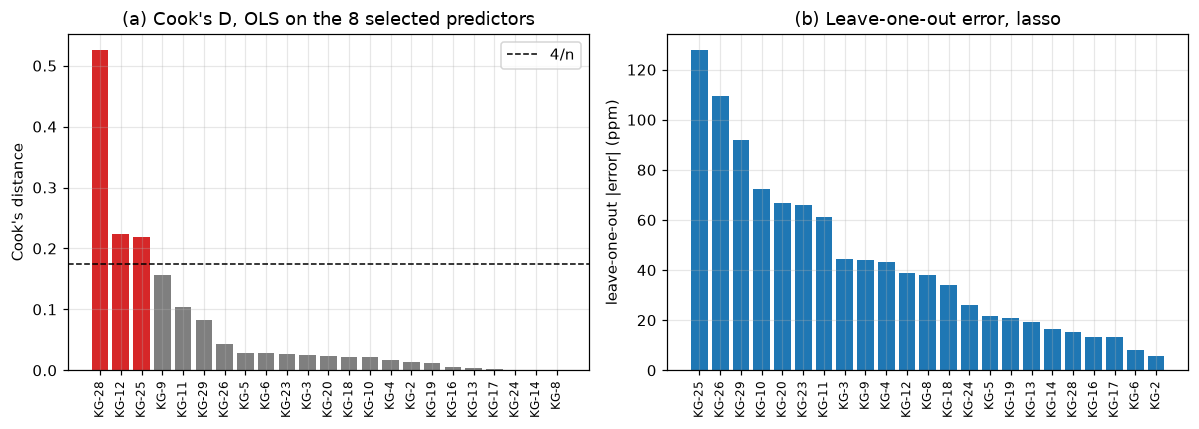

Selected predictors used for Cook's D: ['Be', 'Ca %', 'Fe %', 'Ga', 'Ge', 'Sb', 'Sr', 'U']


,sample,layer,lithology,y,loo_abs_error_ppm,shift_in_other_predictions_ppm,cooks_distance,leverage,cooks_flag_4_over_n
21,KG-28,UPL,Phosphorite,585.82,15.42,3.12,0.53,0.61,True
9,KG-12,MPL,Dolomatic Phosphorite,363.03,38.76,3.34,0.22,0.49,True
19,KG-25,UPL,Phosphorite,643.59,127.77,8.88,0.22,0.26,True
6,KG-9,LPL,Phosphorite,419.10,44.16,5.47,0.16,0.43,False
8,KG-11,MPL,Dolomatic Phosphorite,96.23,61.16,7.54,0.10,0.41,False


In [13]:
# Influence: (1) leave-one-out refit of the selected model at its tuned hyper-parameters,
#            (2) classical Cook's distance from an OLS refit on the selected predictors (approximate).
def selected_features(name, est):
    steps = est.regressor_.named_steps
    if name == "lasso":
        mask = steps["model"].coef_ != 0
    elif name == "ols_kbest":
        mask = steps["select"].get_support()
    else:
        c = np.abs(steps["model"].coef_); mask = c >= np.sort(c)[-5]
    return [str(x) for x in np.array(PREDICTORS)[mask]]

fixed = clone(fitted[SELECTED])
full_fit_pred = clone(fixed).fit(Xtr, ytr).predict(Xtr)
inf_rows = []
for i in range(len(train)):
    keep = np.arange(len(train)) != i
    m = clone(fixed).fit(Xtr.iloc[keep], ytr[keep])
    inf_rows.append({"sample": train["sample"][i], "layer": train["layer"][i], "lithology": train["lithology"][i], "y": ytr[i],
                     "loo_abs_error_ppm": abs(ytr[i] - m.predict(Xtr.iloc[[i]])[0]),
                     "shift_in_other_predictions_ppm": float(np.sqrt(np.mean((m.predict(Xtr.iloc[keep]) - full_fit_pred[keep]) ** 2)))})
infl = pd.DataFrame(inf_rows)
feat = selected_features(SELECTED, fitted[SELECTED])
Zs = StandardScaler().fit_transform(np.log10(Xtr[feat]))
ols_fit = sm.OLS(ytr, sm.add_constant(Zs)).fit()
ginf = ols_fit.get_influence()
infl["cooks_distance"] = ginf.cooks_distance[0]
infl["leverage"] = ginf.hat_matrix_diag
infl["cooks_flag_4_over_n"] = infl["cooks_distance"] > 4 / len(train)
infl.to_csv(RES / "influence.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
o = infl.sort_values("cooks_distance", ascending=False)
ax[0].bar(o["sample"], o["cooks_distance"], color=["tab:red" if f else "tab:gray" for f in o["cooks_flag_4_over_n"]])
ax[0].axhline(4 / len(train), c="k", ls="--", lw=1, label="4/n"); ax[0].tick_params(axis="x", rotation=90, labelsize=8)
ax[0].set_ylabel("Cook's distance"); ax[0].set_title(f"(a) Cook's D, OLS on the {len(feat)} selected predictors"); ax[0].legend()
o2 = infl.sort_values("loo_abs_error_ppm", ascending=False)
ax[1].bar(o2["sample"], o2["loo_abs_error_ppm"], color="tab:blue"); ax[1].tick_params(axis="x", rotation=90, labelsize=8)
ax[1].set_ylabel("leave-one-out |error| (ppm)"); ax[1].set_title(f"(b) Leave-one-out error, {SELECTED}")
plt.tight_layout(); plt.savefig(FIG / "influence.png", bbox_inches="tight", dpi=150); plt.show()
print("Selected predictors used for Cook's D:", feat)
display(infl.sort_values("cooks_distance", ascending=False).head(5).round(2))

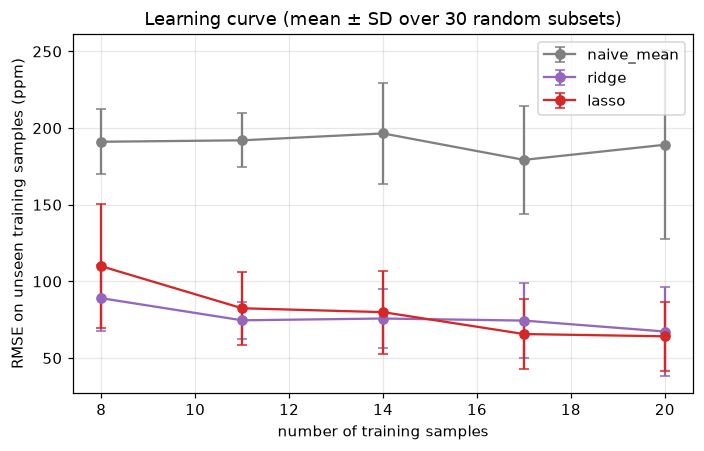

Warnings during learning-curve fits: 0


model,lasso,naive_mean,ridge
n_train,,,
8,109.9,191.1,89.1
11,82.5,192.0,74.6
14,79.9,196.5,75.8
17,65.7,179.3,74.4
20,64.2,189.1,67.3


In [14]:
# Learning curve: how does out-of-sample error change with the number of training samples?
# Each point: 30 random subsets of the training samples; hyper-parameters re-tuned (3-fold CV) on each subset;
# error measured on the training samples NOT in the subset. The frozen test set is not used.
def fit_tuned(name, X, y, seed):
    est, _, _ = CANDIDATES[name]
    grid = {"regressor__model__alpha": np.logspace(-2, 3, 15) if name == "ridge" else np.logspace(-3, 0, 15)}
    return GridSearchCV(est, grid, cv=KFold(3, shuffle=True, random_state=seed), scoring="neg_root_mean_squared_error").fit(X, y)

SIZES, DRAWS = [8, 11, 14, 17, 20], 30
rng_lc = np.random.default_rng(SEED)
idx_all = np.arange(len(train))
lc_rows = []
with warnings.catch_warnings(record=True) as lc_warnings:
    warnings.simplefilter("always")
    for n in SIZES:
        for dr in range(DRAWS):
            sub = rng_lc.choice(idx_all, size=n, replace=False)
            rest = np.setdiff1d(idx_all, sub)
            Xs, ys, Xr, yr = Xtr.iloc[sub], ytr[sub], Xtr.iloc[rest], ytr[rest]
            lc_rows.append({"n_train": n, "model": "naive_mean", "rmse": rmse(yr, np.full(len(yr), ys.mean()))})
            for name in ("ridge", "lasso"):
                lc_rows.append({"n_train": n, "model": name, "rmse": rmse(yr, fit_tuned(name, Xs, ys, SEED + dr).predict(Xr))})
lc = pd.DataFrame(lc_rows)
lc_sum = lc.groupby(["model", "n_train"])["rmse"].agg(["mean", "std"]).reset_index()
lc_sum.to_csv(RES / "learning_curve.csv", index=False)
fig, a = plt.subplots(figsize=(6.5, 4.2))
for name, c in [("naive_mean", "gray"), ("ridge", "tab:purple"), ("lasso", "tab:red")]:
    s = lc_sum[lc_sum.model == name]
    a.errorbar(s["n_train"], s["mean"], yerr=s["std"], marker="o", capsize=3, label=name, color=c)
a.set_xlabel("number of training samples"); a.set_ylabel("RMSE on unseen training samples (ppm)")
a.set_title("Learning curve (mean ± SD over 30 random subsets)"); a.legend()
plt.tight_layout(); plt.savefig(FIG / "learning_curve.png", bbox_inches="tight", dpi=150); plt.show()
print("Warnings during learning-curve fits:", len(lc_warnings))
display(lc_sum.pivot(index="n_train", columns="model", values="mean").round(1))

In [15]:
# Critical slices: where is the error concentrated?  (training samples, out-of-fold)
def slice_table(df_, by, label):
    g = df_.groupby(by, observed=True)
    t = g.agg(n=("resid", "size"), rmse=("resid", lambda r: float(np.sqrt(np.mean(r ** 2)))), mean_error=("resid", "mean"),
              mean_observed=("y", "mean")).reset_index().rename(columns={by: "slice"})
    t.insert(0, "slice_type", label)
    t["rmse_pct_of_mean_observed"] = 100 * t["rmse"] / t["mean_observed"]
    t["slice"] = t["slice"].astype(str)
    return t
oof_df["level"] = pd.qcut(oof_df["y"], 3, labels=["low observed ∑REY", "mid observed ∑REY", "high observed ∑REY"])
slices = pd.concat([slice_table(oof_df, "layer", "layer"), slice_table(oof_df, "lith_group", "lithology group"),
                    slice_table(oof_df, "level", "observed level")], ignore_index=True)
slices.to_csv(RES / "slices_train_oof.csv", index=False)
test_slices = pd.DataFrame({"layer": test["layer"], "lithology": test["lithology"], "resid": test_resid, "y": yte})
test_slices = test_slices.assign(abs_error=test_slices["resid"].abs())
test_slices.to_csv(RES / "slices_test.csv", index=False)
display(slices.round(1))

# Calibration: regress observed on out-of-fold predicted. A slope near 1 means predictions are neither shrunken nor inflated.
cal = sm.OLS(ytr, sm.add_constant(oof)).fit()
cal_slope = float(cal.params[1]); cal_lo, cal_hi = cal.conf_int()[1]
print(f"Calibration slope (observed on out-of-fold predicted): {cal_slope:.2f}, 95% CI {cal_lo:.2f} to {cal_hi:.2f}")
print("Test-set slices have only 2 samples per layer and no chert; they are in results/slices_test.csv but carry little weight.")

,slice_type,slice,n,rmse,mean_error,mean_observed,rmse_pct_of_mean_observed
0,layer,LPL,8,38.3,-10.4,276.3,13.9
1,layer,MPL,9,37.2,5.2,355.7,10.4
2,layer,UPL,6,82.3,8.3,478.9,17.2
3,lithology group,chert-bearing,3,27.1,-21.7,143.2,18.9
4,lithology group,dolomitic phosphorite,5,41.6,-10.5,164.9,25.2
5,lithology group,phosphorite,15,60.0,8.7,468.8,12.8
6,observed level,low observed ∑REY,8,34.6,-7.6,151.2,22.9
7,observed level,mid observed ∑REY,7,54.2,-46.9,378.1,14.3
8,observed level,high observed ∑REY,8,65.8,50.2,553.7,11.9


Calibration slope (observed on out-of-fold predicted): 1.07, 95% CI 0.92 to 1.21
Test-set slices have only 2 samples per layer and no chert; they are in results/slices_test.csv but carry little weight.


## 7. Complexity versus gain

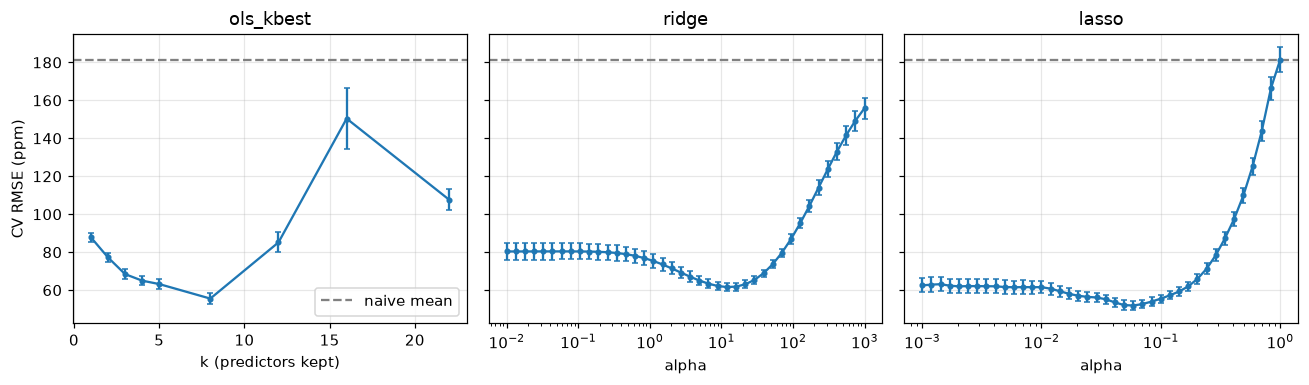

,model,n_features_used,cv_rmse_mean,test_rmse,cv_gain_vs_naive_pct,test_gain_vs_naive_pct
0,naive_mean,0,181.3,169.4,0.0,0.0
1,layer_mean,0,182.9,142.6,-0.8,15.8
2,ols_all,35,80.4,101.4,55.7,40.1
3,ols_kbest,8,55.5,86.6,69.4,48.9
4,ridge,35,61.6,42.8,66.0,74.7
5,lasso,8,51.9,82.1,71.4,51.5


Naive mean -> lasso: CV RMSE 181 -> 52 ppm (71% lower).
lasso vs the simpler OLS-on-k-best: CV RMSE 51.9 vs 55.5 ppm (difference +3.6; CV SD about 17).


In [16]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for a, (name, pcol, lab, logx) in zip(ax, [("ols_kbest", "param_regressor__select__k", "k (predictors kept)", False),
                                           ("ridge", "param_regressor__model__alpha", "alpha", True),
                                           ("lasso", "param_regressor__model__alpha", "alpha", True)]):
    t = tuning[tuning.model == name].copy(); t[pcol] = t[pcol].astype(float); t = t.sort_values(pcol)
    a.errorbar(t[pcol], -t["mean_test_score"], yerr=t["std_test_score"] / np.sqrt(50), marker="o", ms=3, capsize=2)
    a.axhline(naive_cv, c="gray", ls="--", label="naive mean"); a.set_title(name); a.set_xlabel(lab)
    if logx: a.set_xscale("log")
ax[0].set_ylabel("CV RMSE (ppm)"); ax[0].legend()
plt.tight_layout(); plt.savefig(FIG / "complexity_curves.png", bbox_inches="tight", dpi=150); plt.show()
cmp_view = comp[["model", "n_features_used", "cv_rmse_mean", "test_rmse", "cv_gain_vs_naive_pct", "test_gain_vs_naive_pct"]].round(1)
display(cmp_view)
base_lin = comp.loc[comp.model == "ols_kbest"].iloc[0]
sel = comp.loc[comp.model == SELECTED].iloc[0]
print(f"Naive mean -> {SELECTED}: CV RMSE {naive_cv:.0f} -> {sel.cv_rmse_mean:.0f} ppm ({sel.cv_gain_vs_naive_pct:.0f}% lower).")
print(f"{SELECTED} vs the simpler OLS-on-k-best: CV RMSE {sel.cv_rmse_mean:.1f} vs {base_lin.cv_rmse_mean:.1f} ppm (difference {base_lin.cv_rmse_mean - sel.cv_rmse_mean:+.1f}; CV SD about {sel.cv_rmse_sd:.0f}).")

## 8. Why the coefficients are not causal
Many predictors are strongly correlated with each other and with ∑REY. The checks below show whether the fitted coefficients are stable and unique. A coefficient is a description of this sample, not an effect of an intervention.

,feature,lasso_coef_ppm_per_SD_log10x,ridge_coef_ppm_per_SD_log10x,lasso_selection_frequency
2,Be,89.07,26.80,0.99
12,Ge,30.22,22.33,0.98
31,U,0.52,18.84,0.61
25,Sr,44.26,16.34,0.52
26,Th,0.00,21.35,0.51
10,Fe %,-1.46,-10.79,0.50
23,Sb,-15.50,-6.81,0.50
4,Ca %,0.58,13.94,0.32
5,Cd,-0.00,-9.44,0.30
11,Ga,-15.72,-5.67,0.30


,Be,Ge,U,Sr,Th,Fe %
Be,1.00,0.63,0.90,0.84,0.53,-0.69
Ge,0.63,1.00,0.53,0.65,0.68,-0.58
U,0.90,0.53,1.00,0.94,0.38,-0.75
Sr,0.84,0.65,0.94,1.00,0.48,-0.76
Th,0.53,0.68,0.38,0.48,1.00,-0.17
Fe %,-0.69,-0.58,-0.75,-0.76,-0.17,1.00


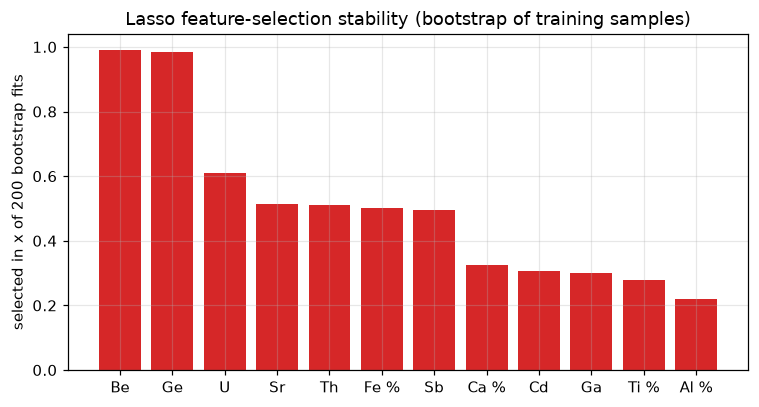

In [17]:
lasso_fit = fitted["lasso"].regressor_.named_steps["model"]
y_scale = float(fitted["lasso"].transformer_.scale_[0])
ridge_fit = fitted["ridge"].regressor_.named_steps["model"]
B = 200
rng_b = np.random.default_rng(SEED)
sel_counts = pd.Series(0, index=PREDICTORS, dtype=int)
with warnings.catch_warnings(record=True) as boot_warnings:
    warnings.simplefilter("always")
    for _ in range(B):
        idx = rng_b.integers(0, len(train), len(train))
        mb = clone(fitted["lasso"]).fit(Xtr.iloc[idx], ytr[idx])
        sel_counts += (mb.regressor_.named_steps["model"].coef_ != 0).astype(int)
sel_freq = sel_counts / B
coef_tbl = pd.DataFrame({"feature": PREDICTORS, "lasso_coef_ppm_per_SD_log10x": lasso_fit.coef_ * y_scale,
                         "ridge_coef_ppm_per_SD_log10x": ridge_fit.coef_ * float(fitted["ridge"].transformer_.scale_[0]),
                         "lasso_selection_frequency": sel_freq.values}).sort_values("lasso_selection_frequency", ascending=False)
coef_tbl.to_csv(RES / "coefficients_stability.csv", index=False)
display(coef_tbl.head(10).round(2))

top = list(coef_tbl["feature"].head(6))
logd = np.log10(Xtr[top])
corr_top = logd.corr().round(2)
display(corr_top)

fig, a = plt.subplots(figsize=(7, 3.8))
t = coef_tbl.head(12)
a.bar(t["feature"], t["lasso_selection_frequency"], color="tab:red")
a.set_ylabel(f"selected in x of {B} bootstrap fits"); a.set_title("Lasso feature-selection stability (bootstrap of training samples)")
plt.tight_layout(); plt.savefig(FIG / "coefficient_stability.png", bbox_inches="tight", dpi=150); plt.show()

In [18]:
# "Swap" test: remove the most frequently selected predictor and re-tune the lasso. If the error barely changes
# and a correlated predictor takes over, the coefficient was never a unique effect of that element.
top1 = coef_tbl["feature"].iloc[0]
keep_cols = [p for p in PREDICTORS if p != top1]
gs_swap = GridSearchCV(pipe(Lasso(max_iter=50000)), {"regressor__model__alpha": np.logspace(-3, 0, 40)}, cv=CV,
                       scoring="neg_root_mean_squared_error", n_jobs=1).fit(Xtr[keep_cols], ytr)
swap_cv = float(-gs_swap.best_score_)
swap_feats = [str(x) for x in np.array(keep_cols)[gs_swap.best_estimator_.regressor_.named_steps["model"].coef_ != 0]]
others = [c for c in PREDICTORS if c != top1]
r_with = {c: float(np.corrcoef(np.log10(Xtr[top1]), np.log10(Xtr[c]))[0, 1]) for c in others}
partner = max(r_with, key=lambda c: abs(r_with[c]))
r_top1_target = float(np.corrcoef(np.log10(Xtr[top1]), ytr)[0, 1])
print(f"Most-selected predictor: {top1} (r with ∑REY on the training samples = {r_top1_target:.2f})")
print(f"Its strongest predictor partner: {partner} (r = {r_with[partner]:.2f} on log10 values)")
print(f"Lasso CV RMSE with all predictors: {cv_stats['lasso'][0]:.1f} ppm | without {top1}: {swap_cv:.1f} ppm")
print(f"Predictors kept without {top1}: {swap_feats}")

Most-selected predictor: Be (r with ∑REY on the training samples = 0.92)
Its strongest predictor partner: Na % (r = 0.92 on log10 values)
Lasso CV RMSE with all predictors: 51.9 ppm | without Be: 67.4 ppm
Predictors kept without Be: ['Cd', 'Cr', 'Cu', 'Fe %', 'Ge', 'Na %', 'Sr', 'Th', 'Ti %', 'Ba', 'U']
